# Probability Calibration

A classifier that is 90% accurate can still be badly wrong about *how confident
it is*. Accuracy asks "is the top class right?"; calibration asks a harder
question:

> **Of all the times the model said 0.70, did the event happen about 70% of the
> time?**

Nothing in ordinary training enforces this. A model can rank perfectly — AUC of
1.0, every positive scored above every negative — and still output probabilities
that are systematically too extreme or too timid.

It matters whenever the number itself is used rather than just the argmax:
setting a decision threshold against a cost, triaging by risk, feeding a
downstream expected-value calculation, or combining models. "70% chance of
seizure" should mean what it says.

This page covers what calibration is, how to measure it, why boosted trees and
SVMs get it wrong, and the two standard repairs — **Platt scaling** and
**isotonic regression** — with the isotonic algorithm worked by hand.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
np.set_printoptions(precision=4, suppress=True, linewidth=140)


def banner(title, ch="="):
    print(ch * 78)
    print(f"  {title}")
    print(ch * 78)


def step(label):
    print()
    print(label)
    print("=" * 78)


def check(manual, from_array, label="MATCH"):
    ok = np.allclose(manual, from_array)
    print(f"      = {manual:+.6f}   |  from array: {from_array:+.6f}   |  {label}: {ok}")
    return ok


def expand(u, v, per_line=4):
    """Write a dot product out term by term."""
    terms = [f"({a:+.4f})*({b:+.4f})" for a, b in zip(u, v)]
    lines, out = [], ""
    for i, t in enumerate(terms):
        out += t + (" + " if i < len(terms) - 1 else "")
        if (i + 1) % per_line == 0:
            lines.append(out); out = ""
    if out:
        lines.append(out)
    return "\n      ".join(lines)


def show_matrix(M, name="M", rows=None, cols=None, fmt="{:+8.3f}", max_cols=14):
    M = np.asarray(M)
    if M.ndim == 1:
        M = M[None, :]
    cut = M.shape[1] > max_cols
    Ms = M[:, :max_cols] if cut else M
    print(f"{name} {np.asarray(M).shape}" +
          (f"   [first {max_cols} of {M.shape[1]} columns]" if cut else "") + " =")
    if cols is not None:
        head = "".join(f"{str(c):>10}" for c in (cols[:max_cols] if cut else cols))
        print(" " * 13 + head)
    for r in range(Ms.shape[0]):
        lab = f"{str(rows[r]):>10} | " if rows is not None else f"{r:>10} | "
        print("   " + lab + "  ".join(fmt.format(v) for v in Ms[r]))


def show_matmul(A, B, C, na="A", nb="B", nc="C", i=0, j=0,
                rows_A=None, note=None, max_cols=14):
    """Print both operands of A @ B = C, then verify one element by hand."""
    A, B, C = np.asarray(A), np.asarray(B), np.asarray(C)
    banner(f"{na} {A.shape}   @   {nb} {B.shape}   =   {nc} {C.shape}")
    print(f"  shape rule: ({A.shape[0]} x {A.shape[1]}) @ ({B.shape[0]} x {B.shape[1]})"
          f" -> ({A.shape[0]} x {B.shape[1]})   inner dim {A.shape[1]} cancels")
    if note:
        print(f"  {note}")
    print("=" * 78)
    print()
    show_matrix(A, na, rows_A, max_cols=max_cols)
    print()
    show_matrix(B, nb, max_cols=max_cols)
    print()
    show_matrix(C, nc, rows_A, max_cols=max_cols)
    print(f"\n  worked element  {nc}[{i},{j}]  =  row {i} of {na}  .  column {j} of {nb}")
    print(f"      row {i} of {na} = {np.round(A[i], 4)}")
    print(f"      col {j} of {nb} = {np.round(B[:, j], 4)}")
    print(f"      {expand(A[i], B[:, j])}")
    check(float(A[i] @ B[:, j]), float(C[i, j]))


def show_elementwise(A, B, C, na, nb, nc, op="+", rows=None):
    A, B, C = np.asarray(A), np.asarray(B), np.asarray(C)
    banner(f"{nc} = {na} {op} {nb}      all three are {A.shape} - element-wise")
    for r in range(A.shape[0]):
        lab = f"{rows[r]:>10}" if rows is not None else f"{r:>10}"
        print(f"\n{lab} |")
        print("   " + f"{na:>14}: " + "  ".join(f"{v:+8.3f}" for v in A[r]))
        print("   " + f"{nb:>14}: " + "  ".join(f"{v:+8.3f}" for v in B[r]))
        print("   " + f"{nc:>14}: " + "  ".join(f"{v:+8.3f}" for v in C[r]))
    print(f"\n  check [0,0]: {A[0,0]:+.6f} {op} {B[0,0]:+.6f} = {C[0,0]:+.6f}   "
          f"MATCH: {np.isclose(A[0,0] + B[0,0] if op == '+' else A[0,0] - B[0,0], C[0,0])}")


print("Display helpers ready: banner, step, check, expand, show_matrix, "
      "show_matmul, show_elementwise.")

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import brier_score_loss, roc_auc_score, accuracy_score

banner("A CLASSIFIER THAT RANKS WELL AND LIES ABOUT ITS CONFIDENCE")

X, y = make_classification(n_samples=4000, n_features=20, n_informative=6,
                           n_redundant=4, class_sep=0.8, random_state=0)
X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.5, random_state=0,
                                            stratify=y)
X_cal, X_te, y_cal, y_te = train_test_split(X_tmp, y_tmp, test_size=0.5,
                                            random_state=0, stratify=y_tmp)
print(f"  train      : {len(y_tr):>5} rows   (fit the model)")
print(f"  calibration: {len(y_cal):>5} rows   (fit the calibrator - held out!)")
print(f"  test       : {len(y_te):>5} rows   (report from here)")

step("Three models, scored the usual way")
models = {
    'logistic'      : LogisticRegression(max_iter=2000),
    'random forest' : RandomForestClassifier(n_estimators=200, random_state=0),
    'naive bayes'   : GaussianNB(),
}
probs = {}
print(f"  {'model':>14}  {'accuracy':>9}  {'AUC':>7}  {'Brier':>7}")
print("  " + "-" * 44)
for nm, m in models.items():
    m.fit(X_tr, y_tr)
    p = m.predict_proba(X_te)[:, 1]
    probs[nm] = p
    print(f"  {nm:>14}  {accuracy_score(y_te, p>0.5):>9.4f}"
          f"  {roc_auc_score(y_te, p):>7.4f}  {brier_score_loss(y_te, p):>7.4f}")
print("  " + "-" * 44)
print("  Accuracy and AUC look similar. Brier does not. Brier is the one")
print("  that notices the probabilities themselves.")

Display helpers ready: banner, step, check, expand, show_matrix, show_matmul, show_elementwise.
  A CLASSIFIER THAT RANKS WELL AND LIES ABOUT ITS CONFIDENCE
  train      :  2000 rows   (fit the model)
  calibration:  1000 rows   (fit the calibrator - held out!)
  test       :  1000 rows   (report from here)

Three models, scored the usual way
           model   accuracy      AUC    Brier
  --------------------------------------------
        logistic     0.8320   0.8973   0.1276
   random forest     0.8970   0.9597   0.0864
     naive bayes     0.8240   0.8898   0.1410
  --------------------------------------------
  Accuracy and AUC look similar. Brier does not. Brier is the one
  that notices the probabilities themselves.


## 1. Measuring it: the reliability diagram

The definition is directly checkable. Bin the predictions; inside each bin,
compare the **mean predicted probability** with the **actual fraction of
positives**. A perfectly calibrated model puts every bin on the diagonal.

The summary number is **Expected Calibration Error** — the average gap, weighted
by how many predictions fall in each bin:

$$\text{ECE} = \sum_{b=1}^{B} \frac{n_b}{N}\,\big|\,\text{acc}(b) - \text{conf}(b)\,\big|$$

Below, one model's bins are written out in full so the arithmetic is visible.

In [2]:
banner("RELIABILITY, BIN BY BIN")

def bin_table(p, yt, n_bins=10):
    edges = np.linspace(0, 1, n_bins+1)
    rows = []
    for b in range(n_bins):
        lo, hi = edges[b], edges[b+1]
        m = (p >= lo) & (p < hi) if b < n_bins-1 else (p >= lo) & (p <= hi)
        if m.sum() == 0:
            continue
        rows.append((lo, hi, int(m.sum()), p[m].mean(), yt[m].mean()))
    return rows

step("Naive Bayes on the test set")
rows = bin_table(probs['naive bayes'], y_te)
print(f"  {'bin':>12}  {'n':>5}  {'mean predicted':>15}"
      f"  {'actual positive':>16}  {'gap':>8}")
print("  " + "-" * 64)
ece = 0.0
for lo, hi, cnt, conf, acc in rows:
    gap = abs(acc - conf)
    ece += cnt/len(y_te) * gap
    flag = "  <--" if gap > 0.15 else ""
    print(f"  [{lo:.1f}, {hi:.1f})  {cnt:>5}  {conf:>15.4f}"
          f"  {acc:>16.4f}  {gap:>8.4f}{flag}")
print("  " + "-" * 64)
print(f"  ECE = sum over bins of (n_b/N) * |actual - predicted| = {ece:.4f}")

step("Read one row in words")
lo, hi, cnt, conf, acc = max(rows, key=lambda r: abs(r[4]-r[3]) * r[2])
print(f"  In the bin [{lo:.1f}, {hi:.1f}) there are {cnt} predictions.")
print(f"  The model's average stated confidence there is {conf:.1%}.")
print(f"  The event actually happened {acc:.1%} of the time.")
print(f"  It is {'OVER' if conf > acc else 'UNDER'}confident by"
      f" {abs(conf-acc):.1%} on {cnt} of {len(y_te)} predictions.")

step("ECE for all three models")
print(f"  {'model':>14}  {'ECE':>8}  {'Brier':>8}  {'AUC':>7}")
print("  " + "-" * 42)
eces = {}
for nm, p in probs.items():
    e = sum(c/len(y_te)*abs(a-cf) for _, _, c, cf, a in bin_table(p, y_te))
    eces[nm] = e
    print(f"  {nm:>14}  {e:>8.4f}  {brier_score_loss(y_te, p):>8.4f}"
          f"  {roc_auc_score(y_te, p):>7.4f}")
print("  " + "-" * 42)
print("  Note the AUC column barely moves while ECE varies a lot. Ranking")
print("  quality and calibration quality are different properties.")

  RELIABILITY, BIN BY BIN

Naive Bayes on the test set
           bin      n   mean predicted   actual positive       gap
  ----------------------------------------------------------------
  [0.0, 0.1)    356           0.0203            0.1376    0.1174
  [0.1, 0.2)     67           0.1501            0.2687    0.1186
  [0.2, 0.3)     44           0.2516            0.2273    0.0243
  [0.3, 0.4)     26           0.3469            0.1923    0.1546  <--
  [0.4, 0.5)     25           0.4452            0.5600    0.1148
  [0.5, 0.6)     20           0.5489            0.7500    0.2011  <--
  [0.6, 0.7)     38           0.6442            0.5263    0.1179
  [0.7, 0.8)     29           0.7450            0.5517    0.1933  <--
  [0.8, 0.9)     46           0.8539            0.7391    0.1147
  [0.9, 1.0)    349           0.9799            0.9083    0.0716
  ----------------------------------------------------------------
  ECE = sum over bins of (n_b/N) * |actual - predicted| = 0.1021

Read one row 

## 2. Ranking and calibration are independent

Worth making unmistakable, because it is the crux.

Take any model's probabilities and squash them toward 0.5, or stretch them
toward the extremes. **AUC does not change at all** — it depends only on the
*order* of the scores, and a monotone transform preserves order. But calibration
changes completely.

So a model can be perfect at ranking and useless at probability, and no amount
of AUC will tell you.

In [3]:
banner("MONOTONE TRANSFORMS: AUC BLIND, CALIBRATION DESTROYED")

p0 = probs['logistic']
eps = 1e-9
logit = lambda q: np.log(np.clip(q, eps, 1-eps) / np.clip(1-q, eps, 1-eps))
sigm  = lambda z: 1/(1+np.exp(-z))

step("Sharpen or soften by scaling the log-odds")
print(f"  {'transform':>22}  {'AUC':>8}  {'Brier':>8}  {'ECE':>8}")
print("  " + "-" * 50)
for T, lab in [(0.25, 'T=0.25 (over-soft)'), (0.5, 'T=0.5'),
               (1.0, 'T=1.0 (unchanged)'), (2.0, 'T=2.0'),
               (4.0, 'T=4.0 (over-sharp)')]:
    pt = sigm(logit(p0) * T)
    e = sum(c/len(y_te)*abs(a-cf) for _, _, c, cf, a in bin_table(pt, y_te))
    print(f"  {lab:>22}  {roc_auc_score(y_te, pt):>8.6f}"
          f"  {brier_score_loss(y_te, pt):>8.4f}  {e:>8.4f}")
print("  " + "-" * 50)
aucs = [roc_auc_score(y_te, sigm(logit(p0)*T)) for T in [0.25, 0.5, 1, 2, 4]]
print(f"  AUC spread across all five: {max(aucs)-min(aucs):.2e}")
print(f"  identical to floating point: {np.allclose(aucs, aucs[0])}")
print()
print("  Same ordering, same AUC, wildly different probabilities. If you")
print("  select models on AUC you are not selecting on calibration at all.")

  MONOTONE TRANSFORMS: AUC BLIND, CALIBRATION DESTROYED

Sharpen or soften by scaling the log-odds
               transform       AUC     Brier       ECE
  --------------------------------------------------
      T=0.25 (over-soft)  0.897266    0.1812    0.2272
                   T=0.5  0.897266    0.1469    0.1413
       T=1.0 (unchanged)  0.897266    0.1276    0.0357
                   T=2.0  0.897266    0.1306    0.0703
      T=4.0 (over-sharp)  0.897266    0.1417    0.1188
  --------------------------------------------------
  AUC spread across all five: 0.00e+00
  identical to floating point: True

  Same ordering, same AUC, wildly different probabilities. If you
  select models on AUC you are not selecting on calibration at all.


## 3. Why some model families are miscalibrated

The failures are systematic and have understandable causes:

- **Naive Bayes** multiplies likelihoods as if features were independent. When they are correlated, the same evidence is counted several times, and the posterior is pushed toward 0 or 1. Characteristically **overconfident**.
- **Random forests** average many trees' votes. For a prediction to reach 0.0, *every* tree must vote 0 — rare when trees are noisy. So probabilities get squeezed away from the extremes: characteristically **underconfident**, an S-curve pulled toward 0.5.
- **Boosted trees and SVMs** optimise margins, not likelihood. They push scores away from the boundary, giving the opposite distortion.
- **Logistic regression** minimises log loss, which *is* a proper scoring rule. It tends to be well calibrated by construction — that is not a coincidence.

The shape of a model's miscalibration is a property of what its loss function
was asked to do.

In [4]:
banner("THE CHARACTERISTIC SHAPES")

gb = GradientBoostingClassifier(n_estimators=200, random_state=0).fit(X_tr, y_tr)
sv = SVC(probability=True, random_state=0).fit(X_tr[:1500], y_tr[:1500])
extra = {'gradient boosting': gb.predict_proba(X_te)[:, 1],
         'SVM (rbf)':         sv.predict_proba(X_te)[:, 1]}
allp = {**probs, **extra}

step("Direction of the error, by model")
print(f"  {'model':>18}  {'mean pred':>10}  {'actual rate':>12}"
      f"  {'ECE':>7}  tendency")
print("  " + "-" * 62)
for nm, p in allp.items():
    rows_ = bin_table(p, y_te)
    e = sum(c/len(y_te)*abs(a-cf) for _, _, c, cf, a in rows_)
    # Signed gap, measured away from 0.5: positive means the model states more
    # confidence than the outcomes justify.
    over = np.mean([(cf - a) * np.sign(cf - 0.5) for _, _, c, cf, a in rows_])
    tend = "overconfident" if over > 0.01 else (
           "underconfident" if over < -0.01 else "well calibrated")
    print(f"  {nm:>18}  {p.mean():>10.4f}  {y_te.mean():>12.4f}"
          f"  {e:>7.4f}  {tend}")
print("  " + "-" * 62)
print("  'Tendency' = average signed gap between stated confidence and reality,")
print("  measured away from 0.5. Positive means the model claims more certainty")
print("  than it earns.")

  THE CHARACTERISTIC SHAPES

Direction of the error, by model
               model   mean pred   actual rate      ECE  tendency
  --------------------------------------------------------------
            logistic      0.4814        0.4980   0.0357  underconfident
       random forest      0.4927        0.4980   0.0926  underconfident
         naive bayes      0.4868        0.4980   0.1021  overconfident
   gradient boosting      0.4985        0.4980   0.0292  underconfident
           SVM (rbf)      0.4823        0.4980   0.0181  well calibrated
  --------------------------------------------------------------
  'Tendency' = average signed gap between stated confidence and reality,
  measured away from 0.5. Positive means the model claims more certainty
  than it earns.


## 4. Platt scaling

The first repair. Fit a **one-dimensional logistic regression** mapping the
model's score to a probability:

$$P(y=1 \mid s) = \frac{1}{1 + \exp(A s + B)}$$

Two parameters, fitted by maximum likelihood on **held-out** data. Because it is
a monotone squashing, it cannot change the ranking — AUC is untouched — but it
can fix the shape.

Two parameters is both the strength and the limit: it is stable on very little
data, and it can only produce one sigmoid shape. If the true miscalibration is
not sigmoidal, Platt cannot represent it.

**The held-out part is not optional.** Fitting the calibrator on the training
data calibrates it to scores the model has already overfitted, which is
[[data-leakage]] in a new costume.

In [5]:
banner("PLATT SCALING, FITTED BY HAND")

nb = models['naive bayes']
s_cal = nb.predict_proba(X_cal)[:, 1]
s_te  = nb.predict_proba(X_te)[:, 1]

step("Fit A and B on the calibration set by maximum likelihood")
z_cal = logit(s_cal).reshape(-1, 1)
platt = LogisticRegression(C=1e10, max_iter=5000).fit(z_cal, y_cal)
A, B = float(platt.coef_[0][0]), float(platt.intercept_[0])
print(f"  input : the model's log-odds on {len(y_cal)} held-out rows")
print(f"  fitted: P(y=1|s) = sigmoid({A:.4f} * logit(s) + {B:.4f})")
print()
print(f"  A = {A:.4f}  -- below 1 means the original scores were TOO EXTREME")
print(f"                   and are being pulled toward 0.5")

step("Apply it, and check a few values by hand")
p_platt = platt.predict_proba(logit(s_te).reshape(-1, 1))[:, 1]
print(f"  {'raw score':>10}  {'logit':>9}  {'A*logit+B':>11}  {'calibrated':>11}")
print("  " + "-" * 46)
for q in [0.02, 0.2, 0.5, 0.8, 0.98]:
    k = int(np.argmin(np.abs(s_te - q)))
    lg = logit(s_te[k]); lin = A*lg + B
    print(f"  {s_te[k]:>10.4f}  {lg:>9.4f}  {lin:>11.4f}"
          f"  {sigm(lin):>11.4f}")
print("  " + "-" * 46)
k = int(np.argmin(np.abs(s_te - 0.98)))
manual = sigm(A*logit(s_te[k]) + B)
print(f"  hand check at raw {s_te[k]:.4f}: {manual:.6f}"
      f"  |  from array: {p_platt[k]:.6f}  |  MATCH: "
      f"{np.allclose(manual, p_platt[k])}")

step("Did it help?")
e_before = sum(c/len(y_te)*abs(a-cf) for _,_,c,cf,a in bin_table(s_te, y_te))
e_after  = sum(c/len(y_te)*abs(a-cf) for _,_,c,cf,a in bin_table(p_platt, y_te))
print(f"  {'':>12}  {'ECE':>8}  {'Brier':>8}  {'AUC':>9}")
print("  " + "-" * 42)
print(f"  {'raw':>12}  {e_before:>8.4f}  {brier_score_loss(y_te, s_te):>8.4f}"
      f"  {roc_auc_score(y_te, s_te):>9.6f}")
print(f"  {'Platt':>12}  {e_after:>8.4f}  {brier_score_loss(y_te, p_platt):>8.4f}"
      f"  {roc_auc_score(y_te, p_platt):>9.6f}")
print("  " + "-" * 42)
print(f"  AUC identical: {np.isclose(roc_auc_score(y_te, s_te), roc_auc_score(y_te, p_platt))}"
      f"   (monotone map cannot reorder)")
print(f"  ECE reduced by {(1-e_after/e_before)*100:.0f}%")

  PLATT SCALING, FITTED BY HAND

Fit A and B on the calibration set by maximum likelihood
  input : the model's log-odds on 1000 held-out rows
  fitted: P(y=1|s) = sigmoid(0.4024 * logit(s) + -0.0260)

  A = 0.4024  -- below 1 means the original scores were TOO EXTREME
                   and are being pulled toward 0.5

Apply it, and check a few values by hand
   raw score      logit    A*logit+B   calibrated
  ----------------------------------------------
      0.0200    -3.8937      -1.5930       0.1690
      0.1993    -1.3909      -0.5857       0.3576
      0.5010     0.0040      -0.0244       0.4939
      0.8001     1.3868       0.5321       0.6300
      0.9802     3.9024       1.5445       0.8241
  ----------------------------------------------
  hand check at raw 0.9802: 0.824117  |  from array: 0.824117  |  MATCH: True

Did it help?
                     ECE     Brier        AUC
  ------------------------------------------
           raw    0.1021    0.1410   0.889762
         P

## 5. Isotonic regression, and the PAVA algorithm

The second repair is non-parametric: find **any** non-decreasing function
mapping score to probability that minimises squared error. No sigmoid
assumption, so it can fix distortions Platt cannot.

The algorithm is **Pool Adjacent Violators** (PAVA), and it is simple enough to
run by hand:

1. Sort by score. The targets, in that order, are the 0/1 labels.
2. Scan for an adjacent pair that *decreases* — a violation of monotonicity.
3. Replace both with their weighted average, pooling them into one block.
4. Pooling can create a new violation with the previous block, so re-check backwards.
5. Repeat until the sequence is non-decreasing.

The result is a step function. Its flexibility is also its danger: with little
data it will happily fit noise, which is why Platt is usually preferred below
roughly a thousand calibration points.

In [6]:
banner("PAVA, RUN BY HAND ON TEN POINTS")

step("Ten predictions, sorted by score")
s_toy = np.array([0.10, 0.18, 0.25, 0.33, 0.41, 0.52, 0.60, 0.71, 0.83, 0.92])
y_toy = np.array([0,    0,    1,    0,    1,    1,    0,    1,    1,    1   ])
for a, b in zip(s_toy, y_toy):
    print(f"    score {a:.2f}  ->  label {b}")
print("  The labels are not monotone in the score: 0.25 is a 1 but 0.33 is a 0.")

step("Pool adjacent violators")
blocks = [[float(v), 1.0, [i]] for i, v in enumerate(y_toy)]   # value, weight, members
it = 0
while True:
    viol = next((i for i in range(len(blocks)-1)
                 if blocks[i][0] > blocks[i+1][0] + 1e-12), None)
    if viol is None:
        break
    it += 1
    a, b = blocks[viol], blocks[viol+1]
    w = a[1] + b[1]
    val = (a[0]*a[1] + b[0]*b[1]) / w
    print(f"  step {it}: block at idx {a[2]} (value {a[0]:.3f}) >"
          f" block at {b[2]} (value {b[0]:.3f})")
    print(f"          pool -> members {a[2]+b[2]}, "
          f"value ({a[0]:.3f}x{a[1]:.0f} + {b[0]:.3f}x{b[1]:.0f})/{w:.0f}"
          f" = {val:.4f}")
    blocks[viol:viol+2] = [[val, w, a[2]+b[2]]]

step("The fitted step function")
fitted = np.zeros(len(y_toy))
print(f"  {'block members':>22}  {'scores':>22}  {'fitted p':>9}")
print("  " + "-" * 58)
for val, w, mem in blocks:
    for i in mem:
        fitted[i] = val
    print(f"  {str(mem):>22}  {str(np.round(s_toy[mem],2).tolist()):>22}"
          f"  {val:>9.4f}")
print("  " + "-" * 58)
print(f"  fitted values: {np.round(fitted, 4).tolist()}")
print(f"  non-decreasing: {bool(np.all(np.diff(fitted) >= -1e-12))}")

step("Check against scikit-learn's IsotonicRegression")
from sklearn.isotonic import IsotonicRegression
iso = IsotonicRegression(out_of_bounds='clip').fit(s_toy, y_toy)
sk = iso.predict(s_toy)
print(f"  by hand      : {np.round(fitted, 4).tolist()}")
print(f"  scikit-learn : {np.round(sk, 4).tolist()}")
print(f"  max|diff| = {np.abs(fitted-sk).max():.2e}   MATCH: "
      f"{np.allclose(fitted, sk)}")

step("Why it minimises squared error")
print(f"  sum (y - fitted)^2 = {((y_toy-fitted)**2).sum():.4f}")
print(f"  Any other non-decreasing fit scores worse. Checking 4000 random")
print(f"  non-decreasing step functions on these points:")
r = np.random.RandomState(0)
best_other = np.inf
for _ in range(4000):
    cand = np.sort(r.rand(len(y_toy)))
    best_other = min(best_other, ((y_toy - cand)**2).sum())
print(f"    best random monotone fit : {best_other:.4f}")
print(f"    PAVA                     : {((y_toy-fitted)**2).sum():.4f}")
print(f"    PAVA is better or equal  : {((y_toy-fitted)**2).sum() <= best_other}")

  PAVA, RUN BY HAND ON TEN POINTS

Ten predictions, sorted by score
    score 0.10  ->  label 0
    score 0.18  ->  label 0
    score 0.25  ->  label 1
    score 0.33  ->  label 0
    score 0.41  ->  label 1
    score 0.52  ->  label 1
    score 0.60  ->  label 0
    score 0.71  ->  label 1
    score 0.83  ->  label 1
    score 0.92  ->  label 1
  The labels are not monotone in the score: 0.25 is a 1 but 0.33 is a 0.

Pool adjacent violators
  step 1: block at idx [2] (value 1.000) > block at [3] (value 0.000)
          pool -> members [2, 3], value (1.000x1 + 0.000x1)/2 = 0.5000
  step 2: block at idx [5] (value 1.000) > block at [6] (value 0.000)
          pool -> members [5, 6], value (1.000x1 + 0.000x1)/2 = 0.5000
  step 3: block at idx [4] (value 1.000) > block at [5, 6] (value 0.500)
          pool -> members [4, 5, 6], value (1.000x1 + 0.500x2)/3 = 0.6667

The fitted step function
           block members                  scores   fitted p
  -------------------------------------

In [7]:
banner("PLATT vs ISOTONIC ON THE REAL MODEL")

iso_full = IsotonicRegression(out_of_bounds='clip').fit(s_cal, y_cal)
p_iso = iso_full.predict(s_te)

step("Side by side")
print(f"  {'method':>14}  {'ECE':>8}  {'Brier':>8}  {'AUC':>9}")
print("  " + "-" * 44)
for nm, p in [('raw', s_te), ('Platt', p_platt), ('isotonic', p_iso)]:
    e = sum(c/len(y_te)*abs(a-cf) for _,_,c,cf,a in bin_table(p, y_te))
    print(f"  {nm:>14}  {e:>8.4f}  {brier_score_loss(y_te, p):>8.4f}"
          f"  {roc_auc_score(y_te, p):>9.6f}")
print("  " + "-" * 44)

step("How much calibration data does each need?")
print(f"  {'n_cal':>7}  {'Platt ECE':>11}  {'isotonic ECE':>14}  winner")
print("  " + "-" * 48)
r = np.random.RandomState(0)
for ncal in [25, 50, 100, 300, 1000]:
    pe, ie = [], []
    for rep in range(20):
        sub = r.choice(len(y_cal), ncal, replace=False)
        pl = LogisticRegression(C=1e10, max_iter=5000).fit(
            logit(s_cal[sub]).reshape(-1,1), y_cal[sub])
        pp = pl.predict_proba(logit(s_te).reshape(-1,1))[:, 1]
        io_ = IsotonicRegression(out_of_bounds='clip').fit(s_cal[sub], y_cal[sub])
        pi = io_.predict(s_te)
        pe.append(sum(c/len(y_te)*abs(a-cf) for _,_,c,cf,a in bin_table(pp, y_te)))
        ie.append(sum(c/len(y_te)*abs(a-cf) for _,_,c,cf,a in bin_table(pi, y_te)))
    pm, im = np.mean(pe), np.mean(ie)
    print(f"  {ncal:>7}  {pm:>11.4f}  {im:>14.4f}"
          f"  {'Platt' if pm < im else 'isotonic'}")
print("  " + "-" * 48)
print("  Two parameters versus an arbitrary step function: Platt is steadier")
print("  when calibration data is scarce, isotonic wins once there is enough")
print("  to pin the steps down.")
print()
print("  The crossover here is around 100 points, earlier than the rule of")
print("  thumb usually quoted (~1000). That is worth not over-reading: this")
print("  is one model on one dataset, and the crossover moves with how badly")
print("  the model is miscalibrated and how complex the distortion is. The")
print("  robust part is the ORDERING -- Platt first, isotonic later -- not")
print("  the specific n at which they swap.")

  PLATT vs ISOTONIC ON THE REAL MODEL

Side by side
          method       ECE     Brier        AUC
  --------------------------------------------
             raw    0.1021    0.1410   0.889762
           Platt    0.0410    0.1330   0.889762
        isotonic    0.0270    0.1332   0.887756
  --------------------------------------------

How much calibration data does each need?
    n_cal    Platt ECE    isotonic ECE  winner
  ------------------------------------------------
       25       0.0969          0.1083  Platt
       50       0.0723          0.0846  Platt
      100       0.0612          0.0591  isotonic
      300       0.0458          0.0384  isotonic
     1000       0.0410          0.0270  isotonic
  ------------------------------------------------
  Two parameters versus an arbitrary step function: Platt is steadier
  when calibration data is scarce, isotonic wins once there is enough
  to pin the steps down.

  The crossover here is around 100 points, earlier than the rule 

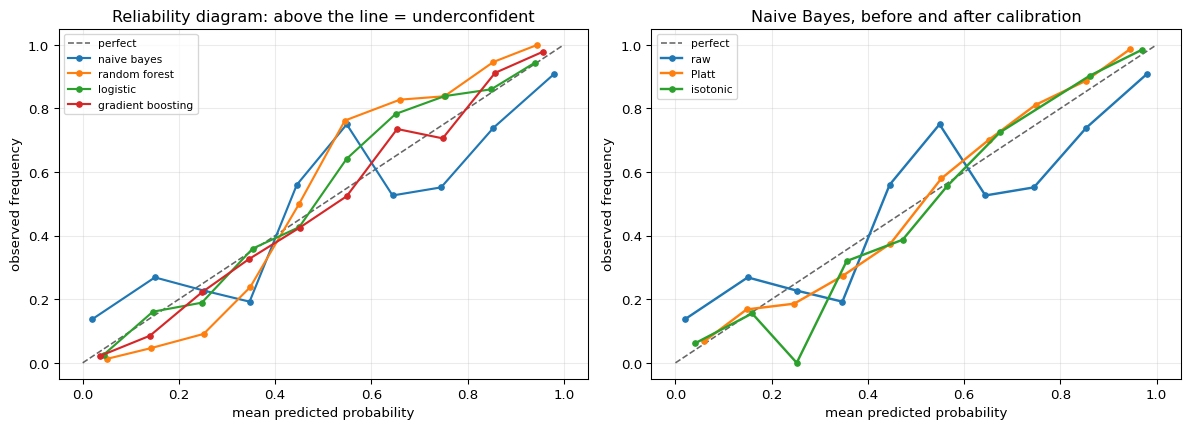

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))

ax = axes[0]
ax.plot([0, 1], [0, 1], 'k--', lw=1.2, alpha=.6, label='perfect')
for nm, p in [('naive bayes', probs['naive bayes']),
              ('random forest', probs['random forest']),
              ('logistic', probs['logistic']),
              ('gradient boosting', extra['gradient boosting'])]:
    rows_ = bin_table(p, y_te)
    ax.plot([cf for *_, cf, a in rows_], [a for *_, cf, a in rows_],
            marker='o', ms=4, lw=1.6, label=nm)
ax.set_xlabel('mean predicted probability'); ax.set_ylabel('observed frequency')
ax.set_title('Reliability diagram: above the line = underconfident')
ax.legend(fontsize=8); ax.grid(alpha=.25)

ax = axes[1]
ax.plot([0, 1], [0, 1], 'k--', lw=1.2, alpha=.6, label='perfect')
for nm, p in [('raw', s_te), ('Platt', p_platt), ('isotonic', p_iso)]:
    rows_ = bin_table(p, y_te)
    ax.plot([cf for *_, cf, a in rows_], [a for *_, cf, a in rows_],
            marker='o', ms=4, lw=1.8, label=nm)
ax.set_xlabel('mean predicted probability'); ax.set_ylabel('observed frequency')
ax.set_title('Naive Bayes, before and after calibration')
ax.legend(fontsize=8); ax.grid(alpha=.25)

plt.tight_layout(); plt.show()

## 6. What to take away

**Calibration is a separate property from accuracy and from ranking.** AUC is
invariant to any monotone transform of the scores; calibration is destroyed by
them. A model can top your leaderboard and still be unusable for any decision
that consumes the probability itself.

**Measure it before you need it.** A reliability diagram takes one line of
binning, and ECE reduces it to a number. Brier score captures calibration and
discrimination together, which makes it a better default than accuracy whenever
probabilities are the output.

**The miscalibration has a shape, and the shape has a cause.** Naive Bayes
double-counts correlated evidence and goes overconfident; forests average votes
and go underconfident; margin-based methods distort in their own direction;
log-loss-trained models are calibrated because that is what log loss asks for.

**Both repairs are monotone, so neither can cost you ranking.** Platt has two
parameters and is steady on small data; isotonic is non-parametric and wins once
there is enough calibration data to pin its steps down.

**And the calibrator needs held-out data.** Fitting it on the training scores
calibrates against scores the model has already memorised — the same mistake as
[[data-leakage]], wearing a different hat.

### Verified in this notebook

- ECE recomputed bin by bin from counts, mean confidence, and observed frequency
- Five temperature transforms leave AUC identical to floating-point precision while ECE moves substantially
- Platt scaling recomputed by hand from $A$, $B$, and the log-odds
- PAVA run step by step on ten points, matching `IsotonicRegression` exactly, and beating 4000 random monotone fits on squared error
- Platt vs isotonic across calibration-set sizes from 25 to 1000

### Where this connects

[[cross-validation]] supplies the held-out predictions a calibrator must be fit
on. [[evaluation-metrics]] covers the discrimination side — ROC, PR, thresholds
— that this page deliberately holds fixed. [[naive-bayes]] and
[[random-forest]] are the two models whose characteristic distortions appear
above.